# 03_random_forest.ipynb — Random Forest Modeling & Forecasting

**UAS ADW** — Perbandingan SARIMA vs Tree-Based ML (Random Forest & XGBoost)

Tujuan: Feature engineering, training Random Forest, rolling origin forecasting (h=1,7,30), evaluasi metrik & feature importance.

In [14]:
# ==============================================================================
# SETUP & IMPORTS
# ==============================================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from joblib import Parallel, delayed

warnings.filterwarnings("ignore")

# Updated path for standard Colab folder structure
# If the 'minggu-1' folder is in your main file explorer sidebar, use '.' or './minggu-1'
DATA_DIR = "./minggu-1" if os.path.exists("./minggu-1") else "."
OUTPUT_DIR = "."
FIGURES_DIR = "."

print(f"Data Source: {os.path.abspath(DATA_DIR)}")

Data Source: /content


In [15]:
from google.colab import files
import os

if not os.path.exists('seri_harian.csv'):
    print("Please upload 'seri_harian.csv' below:")
    uploaded = files.upload()
else:
    print("'seri_harian.csv' is already uploaded!")

'seri_harian.csv' is already uploaded!


In [16]:
# ==============================================================================
# LOAD DATA
# ==============================================================================
df = pd.read_csv(os.path.join(DATA_DIR, "seri_harian.csv"), parse_dates=["tanggal"])
df.set_index("tanggal", inplace=True)
df = df.asfreq("D")
komoditas = ["cabe_rawit", "bawang_merah", "beras_premium"]

print(f"Data: {len(df)} hari | Komoditas: {komoditas}")
print(f"Range: {df.index.min()} s/d {df.index.max()}")

Data: 1339 hari | Komoditas: ['cabe_rawit', 'bawang_merah', 'beras_premium']
Range: 2023-01-01 00:00:00 s/d 2026-08-31 00:00:00


In [17]:
# ==============================================================================
# FEATURE ENGINEERING (Lags, Rolling Stats, Calendar)
# ==============================================================================
def create_features(series, lags=[1, 2, 3, 7, 14, 30], windows=[7, 14, 30]):
    """Buat features untuk time series forecasting."""
    df_feat = pd.DataFrame(index=series.index)
    df_feat["target"] = series.values

    # Lag features
    for lag in lags:
        df_feat[f"lag_{lag}"] = series.shift(lag)

    # Rolling statistics (shift(1) untuk hindari leakage)
    for w in windows:
        df_feat[f"roll_mean_{w}"] = series.shift(1).rolling(w).mean()
        df_feat[f"roll_std_{w}"] = series.shift(1).rolling(w).std()

    # Calendar features
    df_feat["dayofweek"] = df_feat.index.dayofweek
    df_feat["month"] = df_feat.index.month
    df_feat["is_weekend"] = (df_feat.index.dayofweek >= 5).astype(int)

    return df_feat.dropna()

# Test feature engineering
test_feat = create_features(df["cabe_rawit"])
print(f"Feature shape: {test_feat.shape}")
print(f"Features: {list(test_feat.columns)}")

Feature shape: (1309, 16)
Features: ['target', 'lag_1', 'lag_2', 'lag_3', 'lag_7', 'lag_14', 'lag_30', 'roll_mean_7', 'roll_std_7', 'roll_mean_14', 'roll_std_14', 'roll_mean_30', 'roll_std_30', 'dayofweek', 'month', 'is_weekend']


In [18]:
# ==============================================================================
# DEFINE ROLLING ORIGIN FOLDS (Same as SARIMA)
# ==============================================================================
folds = [
    ("Fold1", df.index[(df.index >= "2023-01-01") & (df.index <= "2024-12-31")],
     df.index[(df.index >= "2025-01-01") & (df.index <= "2025-06-30")]),
    ("Fold2", df.index[(df.index >= "2023-01-01") & (df.index <= "2025-06-30")],
     df.index[(df.index >= "2025-07-01") & (df.index <= "2025-12-31")]),
    ("Fold3", df.index[(df.index >= "2023-01-01") & (df.index <= "2025-12-31")],
     df.index[(df.index >= "2026-01-01") & (df.index <= "2026-08-31")]),
]

horizons = [1, 7, 30]
max_h = max(horizons)

for fold_name, train_idx, test_idx in folds:
    print(f"{fold_name}: Train {train_idx[0].date()} to {train_idx[-1].date()} | Test {test_idx[0].date()} to {test_idx[-1].date()} | n_test={len(test_idx)}")

Fold1: Train 2023-01-01 to 2024-12-31 | Test 2025-01-01 to 2025-06-30 | n_test=181
Fold2: Train 2023-01-01 to 2025-06-30 | Test 2025-07-01 to 2025-12-31 | n_test=184
Fold3: Train 2023-01-01 to 2025-12-31 | Test 2026-01-01 to 2026-08-31 | n_test=243


In [19]:
# ==============================================================================
# ROLLING ORIGIN FORECASTING WITH RANDOM FOREST
# ==============================================================================
import time

def rf_forecast_one_fold(series, fold_name, train_idx, test_idx, horizons, max_h, n_estimators=200):
    """Rolling origin forecast untuk Random Forest (fit ulang tiap origin)."""
    results = {h: {"y_true": [], "y_pred": [], "dates": []} for h in horizons}
    n_origin = len(test_idx) - max_h + 1

    for i in range(n_origin):
        origin = test_idx[i]
        train_series = series.loc[:origin]

        # Create features
        train_feat = create_features(train_series)
        if len(train_feat) < 50:
            continue

        X_train = train_feat.drop("target", axis=1)
        y_train = train_feat["target"]

        # Train RF
        rf = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=10,
            min_samples_split=5,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        )
        rf.fit(X_train, y_train)

        # Predict untuk tiap horizon
        for h in horizons:
            target_date = test_idx[i + h - 1]

            # Buat features untuk target_date menggunakan history up to origin
            hist_series = series.loc[:origin]
            if len(hist_series) < 30:
                continue

            feat_row = {}
            # Lags
            for lag in [1, 2, 3, 7, 14, 30]:
                if len(hist_series) >= lag:
                    feat_row[f"lag_{lag}"] = hist_series.iloc[-lag]
                else:
                    feat_row[f"lag_{lag}"] = np.nan
            # Rolling
            for w in [7, 14, 30]:
                if len(hist_series) >= w:
                    recent = hist_series.iloc[-w:]
                    feat_row[f"roll_mean_{w}"] = recent.mean()
                    feat_row[f"roll_std_{w}"] = recent.std()
                else:
                    feat_row[f"roll_mean_{w}"] = np.nan
                    feat_row[f"roll_std_{w}"] = np.nan
            # Calendar
            feat_row["dayofweek"] = target_date.dayofweek
            feat_row["month"] = target_date.month
            feat_row["is_weekend"] = int(target_date.dayofweek >= 5)

            X_pred = pd.DataFrame([feat_row])

            try:
                y_pred = rf.predict(X_pred)[0]
                y_true = float(series.loc[target_date])

                results[h]["y_true"].append(y_true)
                results[h]["y_pred"].append(y_pred)
                results[h]["dates"].append(target_date)
            except Exception as e:
                continue

    return results

# Jalankan untuk semua komoditas dan fold
all_forecasts = []

for fold_name, train_idx, test_idx in folds:
    print(f"\n=== {fold_name} ===")

    for col in komoditas:
        print(f"  {col} ...", end=" ", flush=True)
        t0 = time.time()

        res = rf_forecast_one_fold(
            df[col], fold_name, train_idx, test_idx, horizons, max_h
        )

        for h in horizons:
            n = len(res[h]["y_true"])
            if n == 0:
                continue
            y_true = np.array(res[h]["y_true"])
            y_pred = np.array(res[h]["y_pred"])

            mae = mean_absolute_error(y_true, y_pred)
            rmse = np.sqrt(mean_squared_error(y_true, y_pred))
            mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

            for i in range(n):
                all_forecasts.append({
                    "fold": fold_name,
                    "komoditas": col,
                    "horizon": h,
                    "date": res[h]["dates"][i],
                    "y_true": y_true[i],
                    "y_pred": y_pred[i],
                    "abs_error": abs(y_true[i] - y_pred[i]),
                    "squared_error": (y_true[i] - y_pred[i])**2,
                    "mae_fold": mae,
                    "rmse_fold": rmse,
                    "mape_fold": mape,
                    "n_obs": n
                })

        print(f"done ({time.time()-t0:.1f}s)")

forecast_df = pd.DataFrame(all_forecasts)
forecast_df.to_csv(os.path.join(OUTPUT_DIR, "rf_forecast_all.csv"), index=False)
print(f"\nTotal forecast points: {len(forecast_df)}")
print(forecast_df.groupby(["fold", "komoditas", "horizon"]).size().unstack(fill_value=0))


=== Fold1 ===
  cabe_rawit ... done (244.9s)
  bawang_merah ... done (217.9s)
  beras_premium ... done (161.5s)

=== Fold2 ===
  cabe_rawit ... done (285.7s)
  bawang_merah ... done (260.9s)
  beras_premium ... done (180.1s)

=== Fold3 ===
  cabe_rawit ... done (461.1s)
  bawang_merah ... done (427.0s)
  beras_premium ... done (284.2s)

Total forecast points: 4689
horizon               1    7    30
fold  komoditas                   
Fold1 bawang_merah   152  152  152
      beras_premium  152  152  152
      cabe_rawit     152  152  152
Fold2 bawang_merah   155  155  155
      beras_premium  155  155  155
      cabe_rawit     155  155  155
Fold3 bawang_merah   214  214  214
      beras_premium  214  214  214
      cabe_rawit     214  214  214


In [20]:
# ==============================================================================
# METRICS SUMMARY TABLE
# ==============================================================================
metrics_summary = forecast_df.groupby(["komoditas", "horizon"]).agg(
    MAE=("abs_error", "mean"),
    RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
    MAPE=("abs_error", lambda x: np.mean(x / forecast_df.loc[x.index, "y_true"]) * 100),
    N=("abs_error", "count")
).reset_index()

print("=== RF Metrics (pooled across folds) ===")
print(metrics_summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

metrics_summary.to_csv(os.path.join(OUTPUT_DIR, "rf_metrics_summary.csv"), index=False)

fold_metrics = forecast_df.groupby(["fold", "komoditas", "horizon"]).agg(
    MAE=("abs_error", "mean"),
    RMSE=("squared_error", lambda x: np.sqrt(x.mean())),
    MAPE=("abs_error", lambda x: np.mean(x / forecast_df.loc[x.index, "y_true"]) * 100),
    N=("abs_error", "count")
).reset_index()

fold_metrics.to_csv(os.path.join(OUTPUT_DIR, "rf_metrics_per_fold.csv"), index=False)
print("\n=== Per-Fold Metrics ===")
print(fold_metrics.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

=== RF Metrics (pooled across folds) ===
    komoditas  horizon      MAE     RMSE  MAPE   N
 bawang_merah        1   323.23   469.17  0.86 521
 bawang_merah        7  1813.90  2463.85  4.78 521
 bawang_merah       30  5554.52  6796.23 14.98 521
beras_premium        1    11.81    30.88  0.07 521
beras_premium        7    40.56    82.28  0.26 521
beras_premium       30    81.92   132.45  0.52 521
   cabe_rawit        1  1185.77  2478.48  2.09 521
   cabe_rawit        7  6594.87 10029.49 12.74 521
   cabe_rawit       30 18035.60 22837.21 39.86 521

=== Per-Fold Metrics ===
 fold     komoditas  horizon      MAE     RMSE  MAPE   N
Fold1  bawang_merah        1   307.30   428.74  0.88 152
Fold1  bawang_merah        7  2066.60  2681.77  5.87 152
Fold1  bawang_merah       30  6406.75  7410.25 18.11 152
Fold1 beras_premium        1     0.52     3.38  0.00 152
Fold1 beras_premium        7     0.75     4.78  0.00 152
Fold1 beras_premium       30    18.99    67.42  0.12 152
Fold1    cabe_rawit     

Grafik tersimpan: ./06_rf_forecast_vs_actual.png


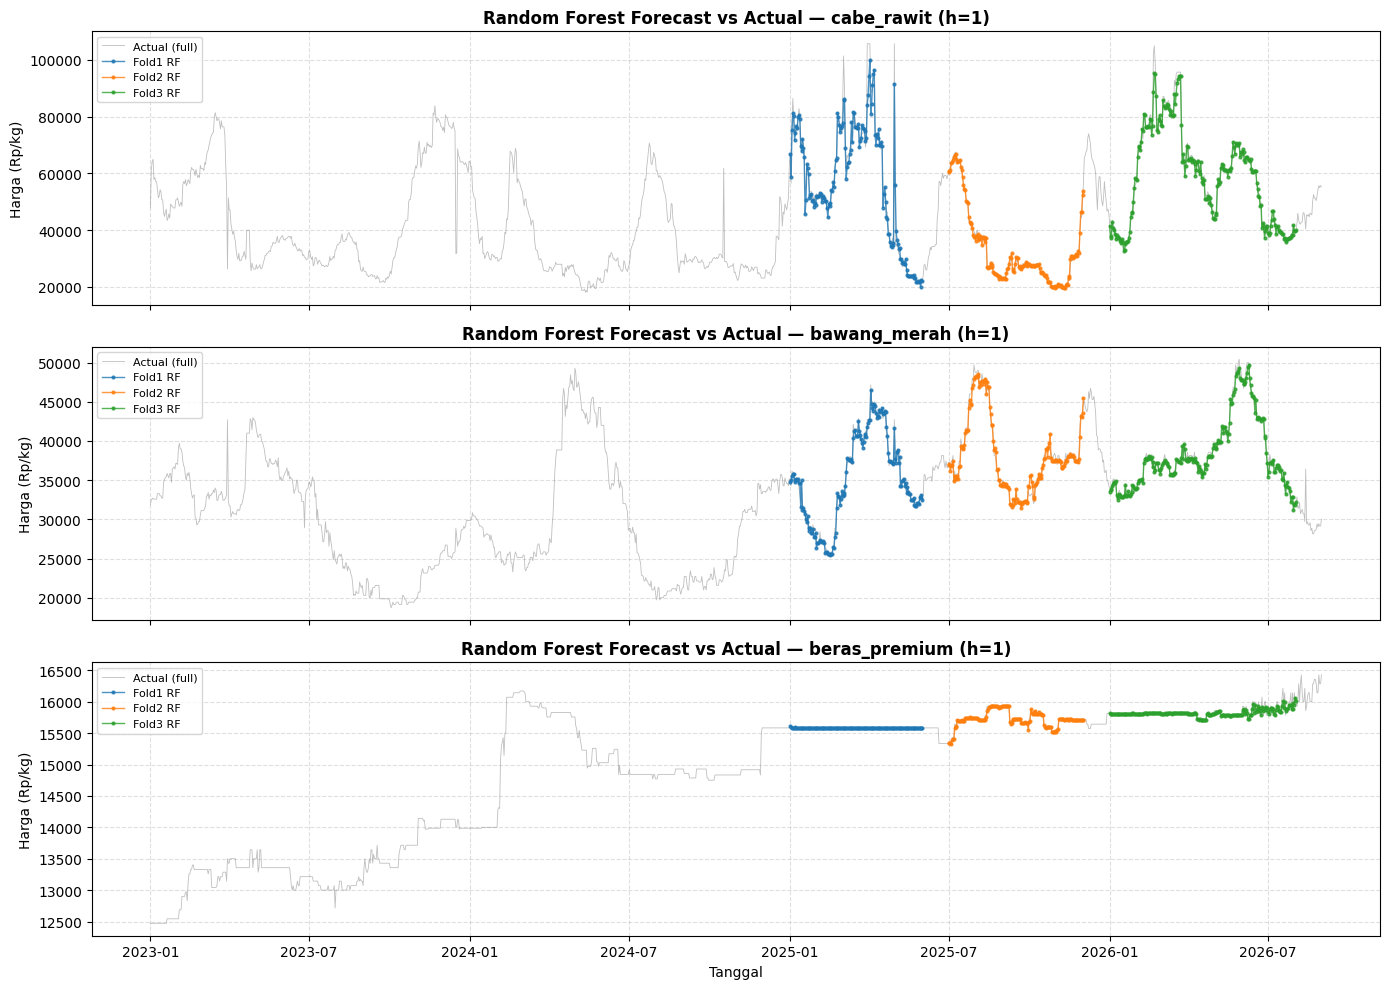

In [21]:
# ==============================================================================
# FORECAST VS ACTUAL PLOTS (h=1)
# ==============================================================================
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

for i, col in enumerate(komoditas):
    ax = axes[i]

    # Actual (full series)
    ax.plot(df.index, df[col], color='gray', linewidth=0.6, alpha=0.5, label='Actual (full)')

    # RF Forecasts h=1
    fc = forecast_df[(forecast_df['komoditas'] == col) & (forecast_df['horizon'] == 1)]

    for fold_name in ['Fold1', 'Fold2', 'Fold3']:
        fcf = fc[fc['fold'] == fold_name]
        if len(fcf):
            ax.plot(fcf['date'], fcf['y_pred'], 'o-', markersize=2, linewidth=1,
                   label=f'{fold_name} RF', alpha=0.8)

    ax.set_title(f"Random Forest Forecast vs Actual — {col} (h=1)", fontsize=12, fontweight='bold')
    ax.set_ylabel('Harga (Rp/kg)')
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, linestyle='--', alpha=0.4)

axes[-1].set_xlabel('Tanggal')
plt.tight_layout()
fig_path = os.path.join(FIGURES_DIR, "06_rf_forecast_vs_actual.png")
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Grafik tersimpan: {fig_path}")
plt.show()


=== cabe_rawit ===
     feature  importance
       lag_1    0.946085
 roll_std_30    0.012422
       lag_2    0.011228
 roll_mean_7    0.004232
      lag_30    0.003437
  roll_std_7    0.003126
 roll_std_14    0.003048
       lag_3    0.002835
roll_mean_14    0.002699
       lag_7    0.002533
roll_mean_30    0.002461
      lag_14    0.002340
   dayofweek    0.002035
       month    0.001409
  is_weekend    0.000109


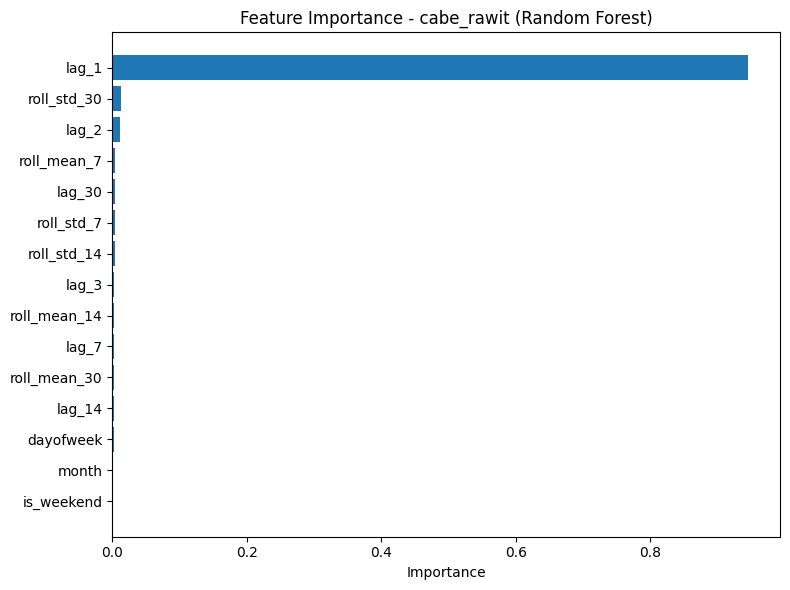


=== bawang_merah ===
     feature  importance
       lag_1    0.932332
       lag_2    0.054852
 roll_std_30    0.002063
  roll_std_7    0.001497
       lag_3    0.001403
 roll_std_14    0.001388
      lag_30    0.001156
      lag_14    0.001079
 roll_mean_7    0.001053
       lag_7    0.000743
roll_mean_30    0.000741
roll_mean_14    0.000679
   dayofweek    0.000500
       month    0.000461
  is_weekend    0.000052


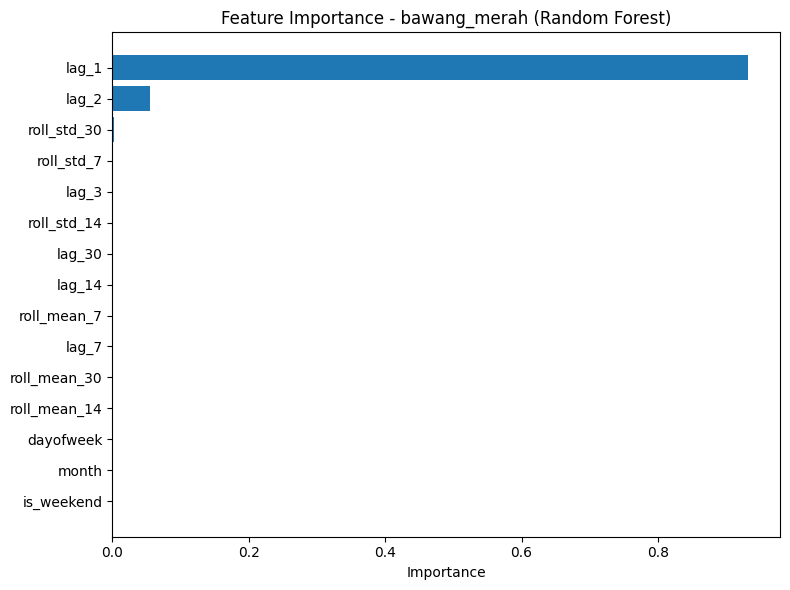


=== beras_premium ===
     feature  importance
       lag_2    0.330470
       lag_3    0.311326
       lag_1    0.208612
roll_mean_14    0.057205
 roll_mean_7    0.053753
roll_mean_30    0.034164
 roll_std_30    0.002858
 roll_std_14    0.000401
       lag_7    0.000277
  roll_std_7    0.000266
       month    0.000181
      lag_30    0.000175
      lag_14    0.000159
   dayofweek    0.000123
  is_weekend    0.000031


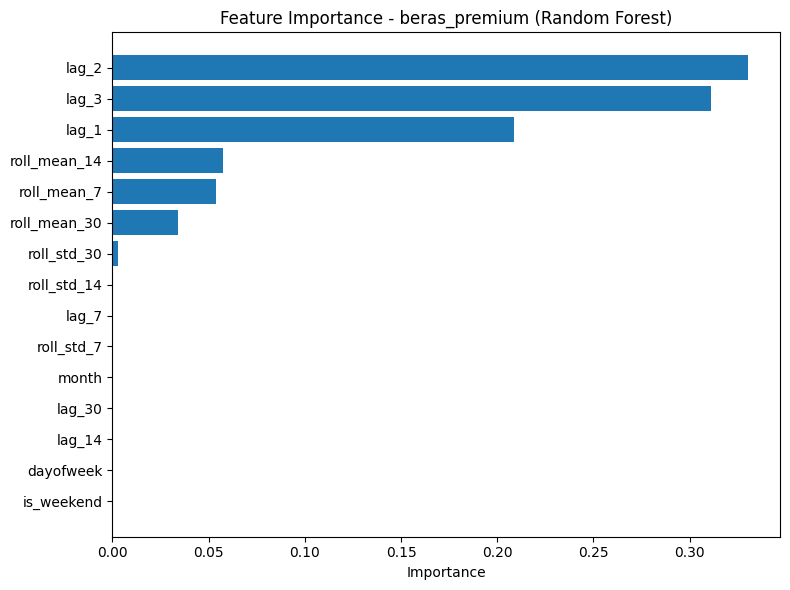

In [22]:
# ==============================================================================
# FEATURE IMPORTANCE (Full Data Model)
# ==============================================================================
importances_dict = {}

for col in komoditas:
    print(f"\n=== {col} ===")
    full_feat = create_features(df[col])
    X = full_feat.drop("target", axis=1)
    y = full_feat["target"]

    rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
    rf.fit(X, y)

    imp = pd.DataFrame({
        "feature": X.columns,
        "importance": rf.feature_importances_
    }).sort_values("importance", ascending=False)

    importances_dict[col] = imp
    imp.to_csv(os.path.join(OUTPUT_DIR, f"rf_feature_importance_{col}.csv"), index=False)

    print(imp.head(15).to_string(index=False))

    # Plot top 15
    plt.figure(figsize=(8, 6))
    top15 = imp.head(15).iloc[::-1]
    plt.barh(top15["feature"], top15["importance"])
    plt.title(f"Feature Importance - {col} (Random Forest)")
    plt.xlabel("Importance")
    plt.tight_layout()
    fig_path = os.path.join(FIGURES_DIR, f"07_rf_feature_importance_{col}.png")
    plt.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.show()

In [23]:
# ==============================================================================
# SAVE FINAL OUTPUTS
# ==============================================================================
print("=== Files Saved ===")
for f in sorted(os.listdir(OUTPUT_DIR)):
    if f.startswith("rf_") or f.startswith("06_") or f.startswith("07_"):
        print(f"  {f}")

print("\n=== RF Metrics Summary ===")
print(metrics_summary.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

=== Files Saved ===
  06_rf_forecast_vs_actual.png
  07_rf_feature_importance_bawang_merah.png
  07_rf_feature_importance_beras_premium.png
  07_rf_feature_importance_cabe_rawit.png
  rf_feature_importance_bawang_merah.csv
  rf_feature_importance_beras_premium.csv
  rf_feature_importance_cabe_rawit.csv
  rf_forecast_all.csv
  rf_metrics_per_fold.csv
  rf_metrics_summary.csv

=== RF Metrics Summary ===
    komoditas  horizon      MAE     RMSE  MAPE   N
 bawang_merah        1   323.23   469.17  0.86 521
 bawang_merah        7  1813.90  2463.85  4.78 521
 bawang_merah       30  5554.52  6796.23 14.98 521
beras_premium        1    11.81    30.88  0.07 521
beras_premium        7    40.56    82.28  0.26 521
beras_premium       30    81.92   132.45  0.52 521
   cabe_rawit        1  1185.77  2478.48  2.09 521
   cabe_rawit        7  6594.87 10029.49 12.74 521
   cabe_rawit       30 18035.60 22837.21 39.86 521
